In [4]:
RUN_DIR = "r3_fr2_a0.2"  #"r4.1_fr3_pflim_f_pfsin_10_pfwidth_1e-2_pflen_0.44"#

In [5]:
import sys
sys.path.append("/global/cfs/projectdirs/m4491/btaczak/SOLPS-BOUT-coupling/scripts")
import os
import sys
import yaml
import numpy as np
from pathlib import Path
import re
import numpy as np
import netCDF4 as nc
import yaml
from scipy.interpolate import interp1d
from boutdata.data import BoutData
from boututils.datafile import DataFile
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.ticker import FormatStrFormatter
from boutdata.data import BoutData
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, fixed
from sibil_io_functions import load_config, sibil_config_summary, confirm, parse_tdata2, parse_block_sizes, write_updated_namelist, _format_value, extract_tdata_first_index, interpolate_dataset, get_midplane_distances_from_psin, vec_summary, set_tdata2_block, get_bout_midplane_distances
from converged_profile_functions import unbiased_convergence, end_biased_convergence

!echo $PWD
data_dir  = f"{RUN_DIR}/numpy"
grid_fname= Path(f"{RUN_DIR}/d3d_shelf_184016.03200_nc3.grd.nc") # Path(f"{RUN_DIR}/d3d_shelf_184016.03506_436_nc3.grd.nc") # 
grid_fname = str(grid_fname)
transport_coeffs = ["Da_t", "Xe_t", "Xi_t", "Vr_mean_txy", "Vexbx_txy", "Vbtildx", "ddr_Tetot_txy", "ddr_Titot_txy", "ddr_nitot_txy"]
jomp = 44
N, l = 0,7

grid = DataFile(grid_fname)
try:
    _ = grid["psi_bdry"]
    has_psi_bdry = True
except Exception:
    has_psi_bdry = False
    
if has_psi_bdry:
    psi_bndry = grid["psi_bdry"]
else:
    psi_bndry = grid["psi_bndry"]

psin = ((grid["psixy"] - grid["psi_axis"]) / (psi_bndry - grid["psi_axis"]))[:,jomp]

psin_mid, sepx_dists_bout = get_bout_midplane_distances(grid_fname)

convergent_transport_coeffs = {}
interplted_transport_coeffs = {}
transport_coeffs = transport_coeffs

for var_name in transport_coeffs:
    if "ddr" in var_name:
        print(var_name)
        convergent_transport_coeffs[var_name] = 1/np.load(f"{data_dir}/{var_name}.npy")
        continue
    var = np.load(f"{data_dir}/{var_name}.npy")
    var_conv = unbiased_convergence(var, None, None)
    convergent_transport_coeffs[var_name] = var_conv

/global/cfs/cdirs/m4491/btaczak/bout-runs/jpar_testing
ddr_Tetot_txy
ddr_Titot_txy
ddr_nitot_txy


/global/cfs/cdirs/m4491/btaczak/bout-runs/jpar_testing
array                 shape                    nt
--------------------------------------------------
Da_t                  (68, 260, 64)            68
Xe_t                  (68, 260, 64)            68
Xi_t                  (68, 260, 64)            68
Vr_mean_txy           (68, 260, 64)            68
Vexbx_txy             (68, 260, 64)            68
Vbtildx               (68, 260, 64)            68
ddr_Tetot_txy         (68, 260, 64)            68
ddr_Titot_txy         (68, 260, 64)            68
ddr_nitot_txy         (68, 260, 64)            68
--------------------------------------------------
OK: all time-dependent arrays have nt = 68


full_report: old argument order detected -> using coeffs, psin, grid = args[0:3]

TOPOLOGY
TOPOLOGY
  nx=260 ny=64 ixseps1=130 ixseps2=260
  jyseps1_1=7 jyseps2_1=32 jyseps1_2=32 jyseps2_2=59
  poloidal cells: inner leg 8, outer leg 4
  -> FEWER THAN 12 CELLS IN A LEG.  C2 parallel derivatives plus a sheath BC on that few points is under-resolved.
  PF_limit cut: ix >= 128 (= ceil(0.98*130)), psi_n = 0.9996; 2 PF cell(s) between the cut and the separatrix.
  PF_filter() overwrites Ni,Ti,Te,U,P,phi,Jpar,Apar but NOT ddt():
  the PF region keeps evolving in CVODE, it is only zeroed in the dumps.
  PF_sink damping that fades out before the separatrix: PFs_width = 0.01, PFs_length = 0.470
  PF_sink damping that fades out before the separatrix: PFs_width = 0.02, PFs_length = 0.440
  Bp < 0.04 T in 217 cells (j = [7, 8, 59, 60]...)
  hthe < 0.04 m in 0 cells
  local q: core rows median 4.94, leg rows max 22.06 -> chi_neo ~ q^2 is x20 larger in the legs
  zShift step across PF connection (j=7

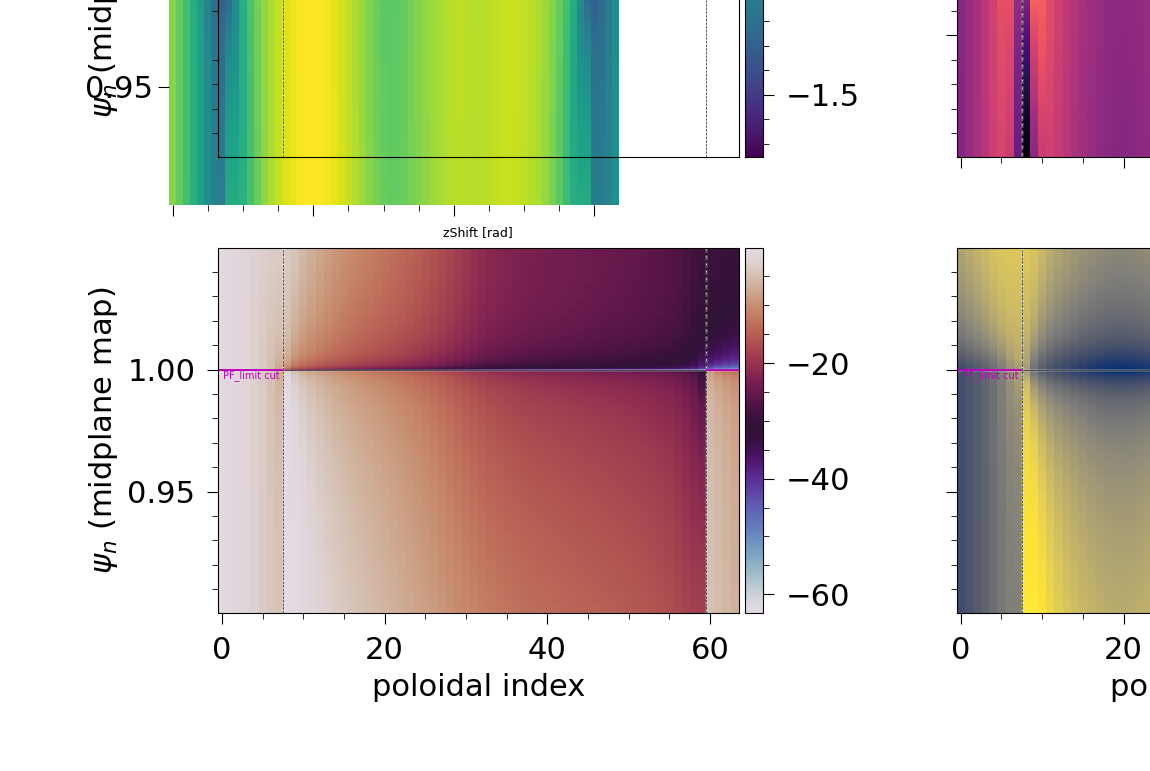


LOADING .npy from /global/cfs/cdirs/m4491/btaczak/bout-runs/jpar_testing/r3_fr2_a0.2/numpy
  Te: Te.npy (68, 260, 64, 64) -> 68 outputs
  Ti: Ti.npy (68, 260, 64, 64) -> 68 outputs
  Ni: Ni.npy (68, 260, 64, 64) -> 68 outputs

0  PROFILE SUMMARY
          t    OMP sep    OMP min    leg sep    leg min  plane min   (total, grid units)
Te        0      53.07      16.02      53.07      16.02      16.02
Te       34      53.12      16.02      53.07      16.02      16.02
Te       67      56.18      16.02      58.32      16.02      16.02
Ti        0      86.61      41.15      86.61      41.15      41.15
Ti       34      86.61      41.15      86.76      41.15      41.15
Ti       67       86.7      41.15      87.07      41.15      41.15
Ni        0     0.3262    0.07141     0.3262    0.07141    0.07141
Ni       34     0.3262    0.07141     0.3262    0.07141    0.07141
Ni       67     0.3269    0.07141     0.3265    0.07141    0.07141
  saved ./crash_diagnostics/r3_fr2_a0.2/profile_summary.png


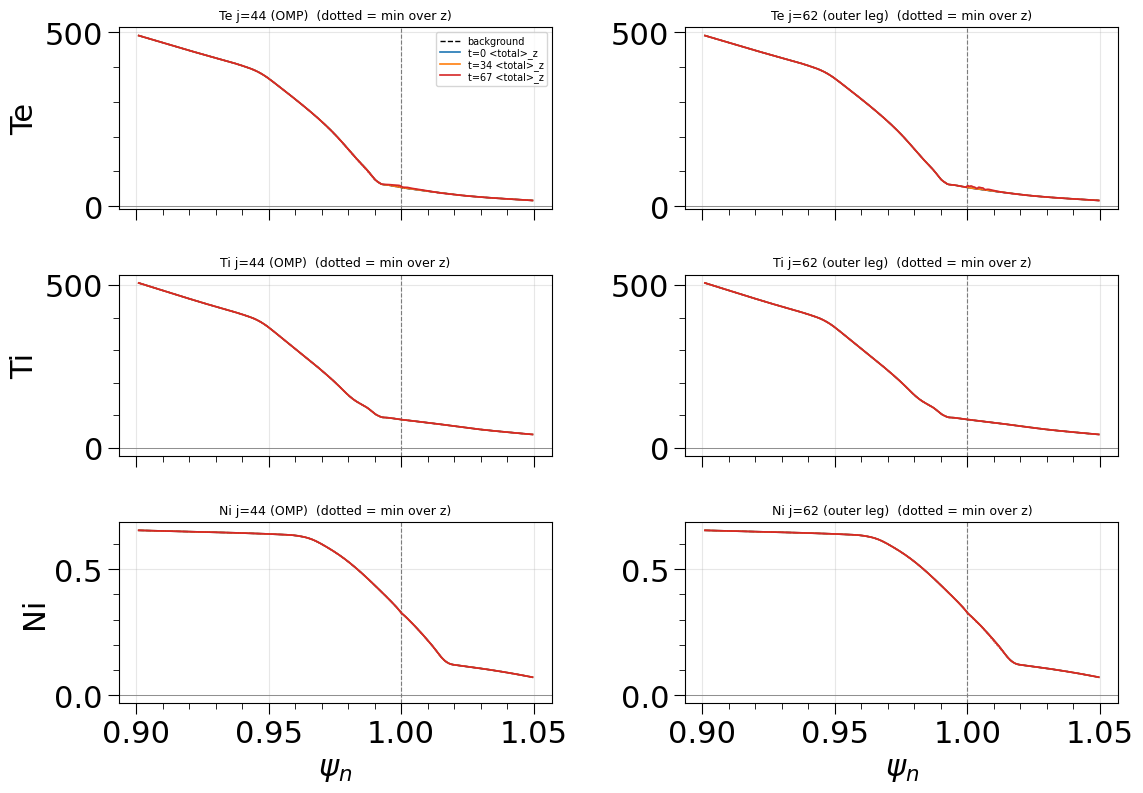


H1  SEPARATRIX DEFECTS (equilibrium kinks, one-cell spikes at ixsep)
  Niexp   max radial kink K within ixsep-3..+2 (upstream rows) = 0.27
  Teexp   max radial kink K within ixsep-3..+2 (upstream rows) = 0.12
  Tiexp   max radial kink K within ixsep-3..+2 (upstream rows) = 0.11
  Jpar0   max radial kink K within ixsep-3..+2 (upstream rows) = 1.15   <-- corner
  Teexp   radial    max K = 0.30 at ix=92 (psi_n~0.9930), j=0 [leg PF]
  Teexp   poloidal  max K = 0.00 at ix=0 (psi_n~0.9010), j=0 [leg PF]
  Tiexp   radial    max K = 0.25 at ix=92 (psi_n~0.9930), j=0 [leg PF]
  Tiexp   poloidal  max K = 0.00 at ix=0 (psi_n~0.9010), j=0 [leg PF]
  Niexp   radial    max K = 0.27 at ix=128 (psi_n~0.9998), j=0 [leg PF]
  Niexp   poloidal  max K = 0.00 at ix=0 (psi_n~0.9010), j=0 [leg PF]
  Jpar0   radial    max K = 1.15 at ix=129 (psi_n~0.9999), j=59 [core]
  Jpar0   poloidal  max K = 2.12 at ix=148 (psi_n~1.0026), j=44 [SOL upstream]
  saved ./crash_diagnostics/r3_fr2_a0.2/equilibrium_kink_map.pn

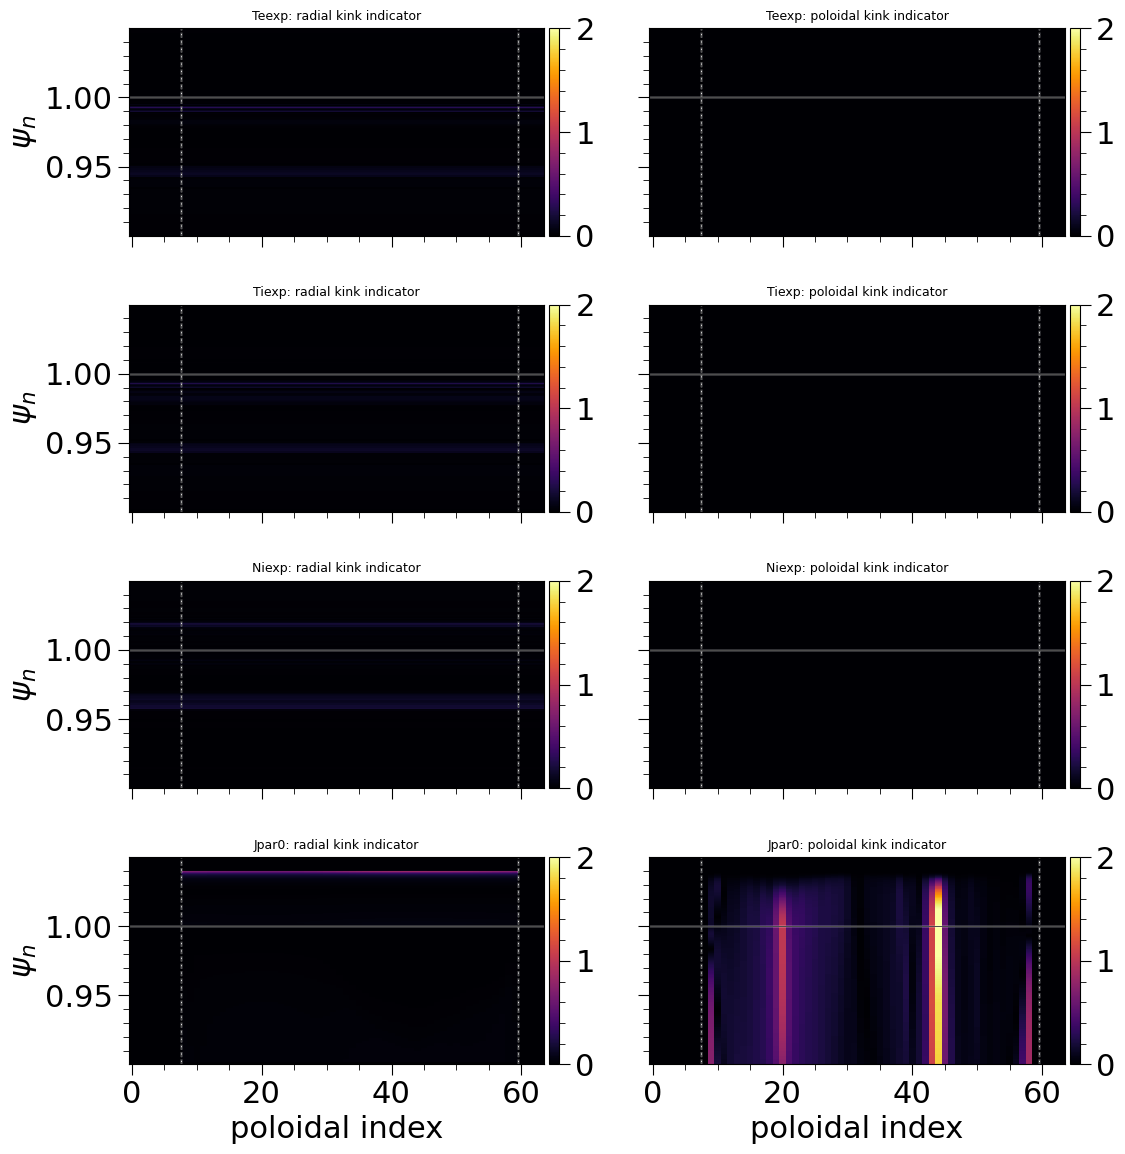

  leg rows: modal spike index ix=95 (psi_n 0.9938), 24% of samples; PF_limit cut at ix=128, separatrix at ix=130
  saved ./crash_diagnostics/r3_fr2_a0.2/spike_locator_Xe_t.png


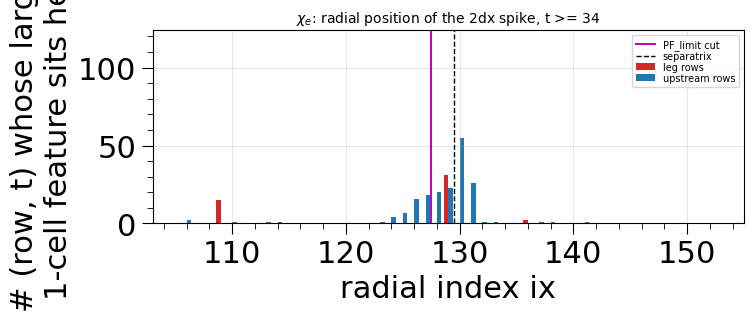

  upstream one-cell spikes within ixsep+-2: 7%

H2  PROFILE COLLAPSE / STIFFNESS

Te: min(total/background) per output
  t=  0  min +1.000 at ix=0 (psi_n 0.9010) iy=0 [leg PF]   cells<0.05: 0
  t=  5  min +1.000 at ix=128 (psi_n 0.9998) iy=36 [core]   cells<0.05: 0
  t= 10  min +1.000 at ix=128 (psi_n 0.9998) iy=37 [core]   cells<0.05: 0
  t= 15  min +1.000 at ix=129 (psi_n 0.9999) iy=0 [leg PF]   cells<0.05: 0
  t= 20  min +1.000 at ix=82 (psi_n 0.9896) iy=17 [core]   cells<0.05: 0
  t= 25  min +0.999 at ix=134 (psi_n 1.0006) iy=0 [leg SOL]   cells<0.05: 0
  t= 30  min +0.999 at ix=82 (psi_n 0.9896) iy=18 [core]   cells<0.05: 0
  t= 35  min +0.999 at ix=128 (psi_n 0.9998) iy=63 [leg PF]   cells<0.05: 0
  t= 40  min +0.999 at ix=128 (psi_n 0.9998) iy=0 [leg PF]   cells<0.05: 0
  t= 45  min +0.997 at ix=129 (psi_n 0.9999) iy=0 [leg PF]   cells<0.05: 0
  t= 50  min +0.994 at ix=147 (psi_n 1.0024) iy=0 [leg SOL]   cells<0.05: 0
  t= 55  min +0.992 at ix=164 (psi_n 1.0053) iy=0 [leg SOL]  

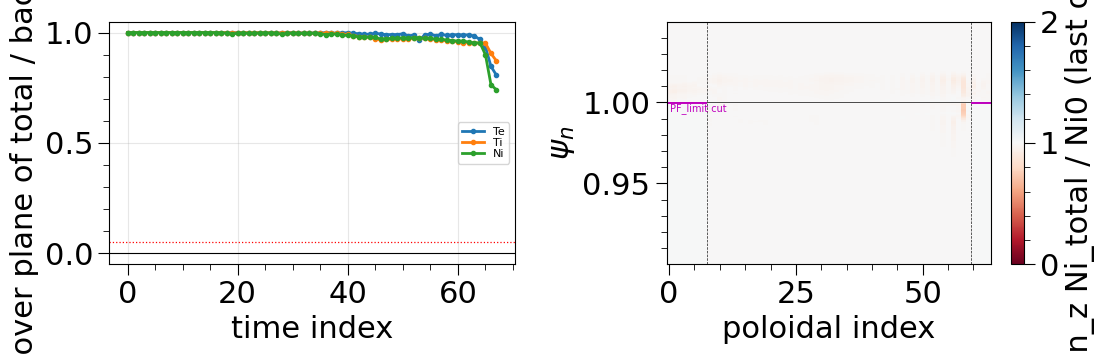

  min total/background: 1.000 at t=0, 0.740 at last output; first < 0.9 at output 65 of 67
  saved ./crash_diagnostics/r3_fr2_a0.2/rhs_cost.png


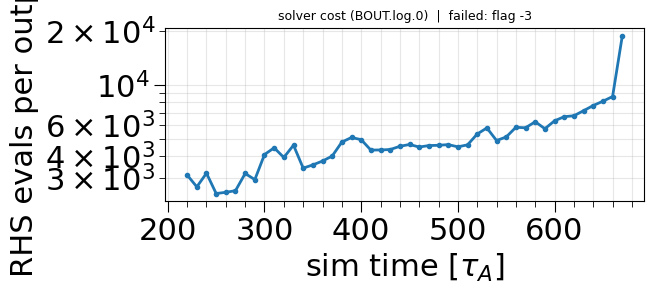

  outputs logged 46, RHS evals first-9 median 2956, last-9 median 7190 (x2.4); failure flag -3

H3  LEGS / SHEATH / PF

Da_t:  growth rate per region (last third of run, 1/tau_A)
   core           final 1.15e+00   gamma +0.007
   SOL upstream   final 1.43e+00   gamma +0.009
   leg SOL        final 1.49e+01   gamma +0.009
   leg PF         final 3.61e+01   gamma +0.003

Xe_t:  growth rate per region (last third of run, 1/tau_A)
   core           final 1.63e+01   gamma +0.009
   SOL upstream   final 9.31e+00   gamma +0.009
   leg SOL        final 3.98e+01   gamma +0.010
   leg PF         final 4.62e+01   gamma +0.004

Xi_t:  growth rate per region (last third of run, 1/tau_A)
   core           final 6.67e+00   gamma +0.008
   SOL upstream   final 4.30e+00   gamma +0.008
   leg SOL        final 5.81e+01   gamma +0.009
   leg PF         final 1.04e+02   gamma +0.006

Vexbx_txy:  growth rate per region (last third of run, 1/tau_A)
   core           final 3.26e-06   gamma +0.030
   SOL upstr

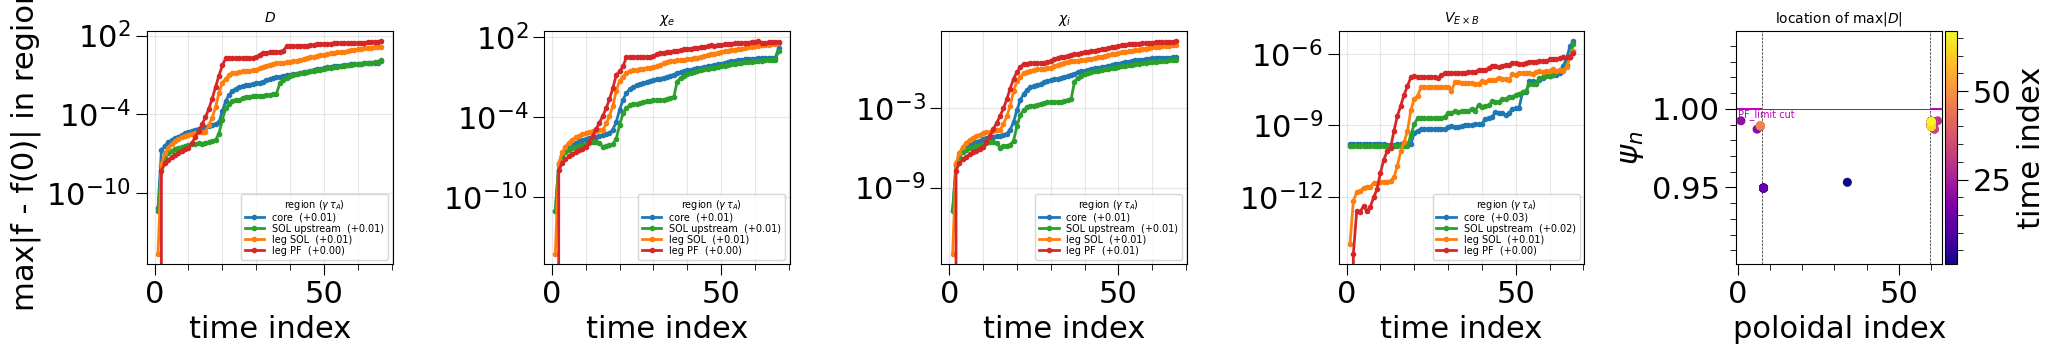

  saved ./crash_diagnostics/r3_fr2_a0.2/crash_map_Xe_t.png


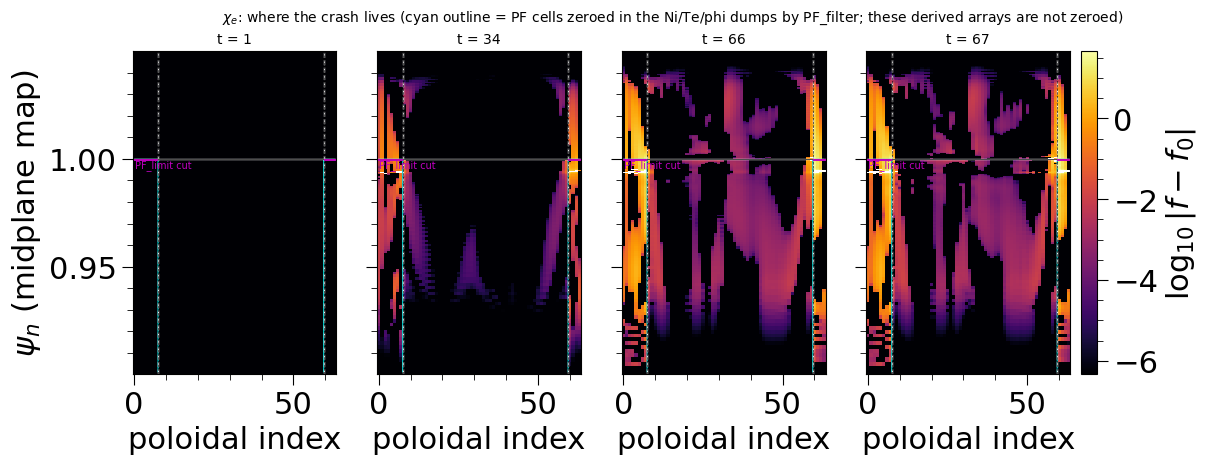

  last third: global max of Xe_t in leg rows 100% of outputs; in the leg PF band ix 125..129 (next to the separatrix) 0%
  leg / upstream amplitude at last output: 2.83e+00
  no *failed*.npy in r3_fr2_a0.2/numpy -- have bout_save_submit also save BOUT.failed.* to enable this section

H4  DRIVE (vorticity terms, needs output_transfer = true)
  no T_C/T_M/T_R/T_G .npy in r3_fr2_a0.2/numpy (needs output_transfer = true and bout_save_submit saving those variables)

VERDICT
  H1 separatrix        SUPPORTED  max kink K 1.15, 7% of upstream spikes at ixsep+-2
  H2a profile collapse not seen   min total/background 0.74 at last output (drop starts at output 65)
  H2b stiffness        SUPPORTED  RHS cost x2.4, flag -3
  H3 legs/sheath       SUPPORTED  max in legs 100% of late outputs (0% in leg PF band next to sep), leg/upstream 2.8e+00
  H4 drive             n/a        not available

All figures written to: /global/cfs/cdirs/m4491/btaczak/bout-runs/jpar_testing/crash_diagnostics/r3_fr2_a0.2
/gl

In [6]:
import sibil_debug_diagnostics as dbg
!echo $PWD
display(dbg.make_debug_widget(convergent_transport_coeffs, psin_mid,
                              jomp=jomp, grid=grid, data_dir=data_dir))
dbg.full_report(convergent_transport_coeffs, psin_mid, grid_fname, jomp=jomp,
                savedir=f"./crash_diagnostics/{RUN_DIR}", run=RUN_DIR)
!echo $PWD